# NSDC Sleep Quality Analysis

## Can daily routines predict sleep quality tonight?

This notebook runs the reusable pipeline and presents the findings. The central question is whether a student's day-to-day deviation from their usual routine adds useful predictive information beyond their sleep history.

The data are observational and self-reported. All statements below describe associations or forecasting performance, not causal effects.

In [1]:
import importlib
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

run = importlib.import_module("sleep_analysis.run_analysis").run

results = run(PROJECT_ROOT, PROJECT_ROOT / "config" / "config.yaml")
TABLES = PROJECT_ROOT / "reports" / "tables"
FIGURES = PROJECT_ROOT / "reports" / "figures"
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

Loading and cleaning data...


Writing data-quality tables...


Running repeated-measures statistics...


Evaluating unseen-participant models...


Evaluating chronological forecasts...


Running importance and leakage checks...


Rendering figures...


Saving final metrics...


## Dataset and data quality

The source workbook has 632 rows and 22 expected fields. The primary prospective subset has known participant IDs, valid study-day values, an observed target, and no repeated participant-date pair. It is an analytical subset, not a replacement for the source data.

,value
raw_rows,632.000
cleaned_rows,632.000
known_participants,45.000
prediction_eligible_rows,530.000
prediction_eligible_participants,45.000
mean_observations_per_known_participant,13.689
wearable_sleep_duration_rows,288.000
resting_heart_rate_rows,140.000
hrv_rows,56.000


,flag,records_flagged
0,Study day outside 1-14,15
1,Duplicate participant-date record,70
2,Implausible time in bed (<2 or >16 hours),5
3,Screen time outside stated 0-60 range,79
4,Stress outside stated 1-5 range,366
5,Nap response inconsistent with nap minutes,0
6,Exercise response inconsistent with duration,4
7,Caffeine response inconsistent with time,24


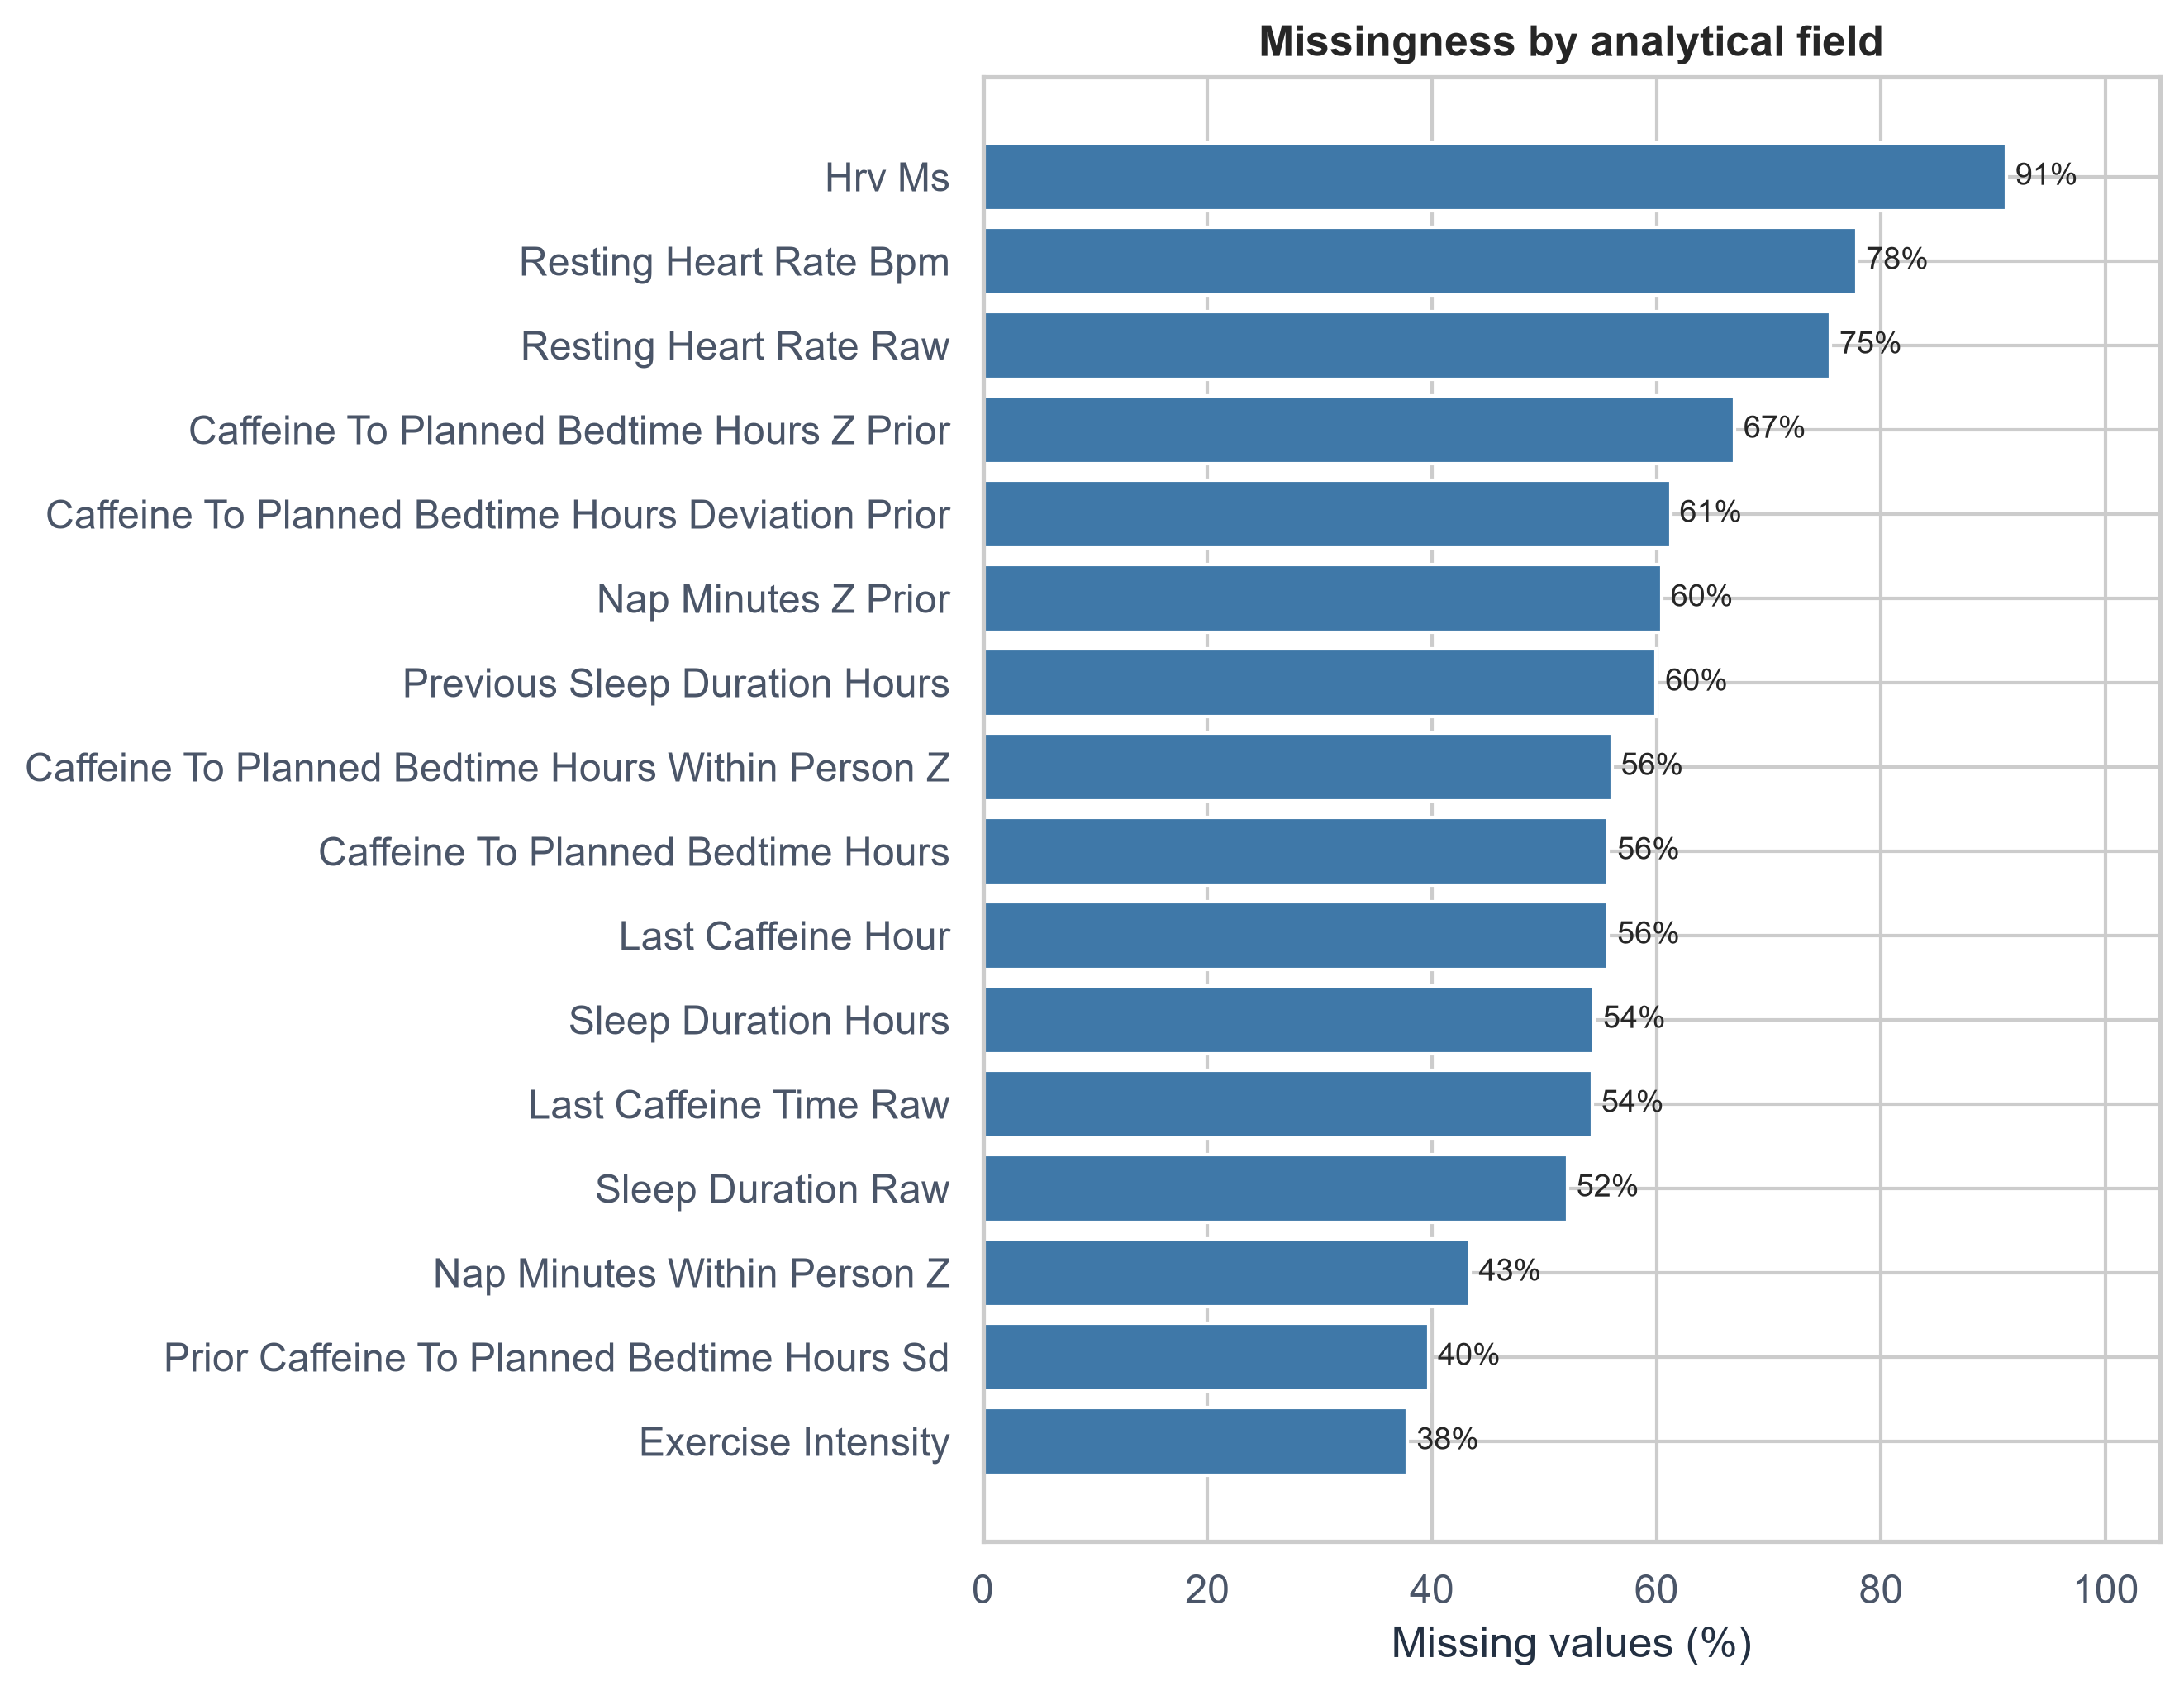

In [2]:
display(pd.read_csv(TABLES / "dataset_summary.csv").T.rename(columns={0: "value"}))
display(pd.read_csv(TABLES / "quality_flags.csv"))
display(Image(filename=str(FIGURES / "01_missingness.png")))

## Sleep-quality distribution

Sleep quality is a bounded self-reported outcome. The distribution and participant-level averages show why a single pooled mean cannot fully represent every participant.

,value
n,530.000
mean,6.638
median,7.000
sd,2.076
q1,5.000
q3,8.000
iqr,3.000
minimum,1.000
maximum,10.000
skewness,-0.732


,sleep_quality,participant_days
0,1.000,9
1,2.000,18
2,3.000,27
3,4.000,30
4,5.000,55
5,6.000,62
6,7.000,118
7,8.000,124
8,9.000,63
9,10.000,24


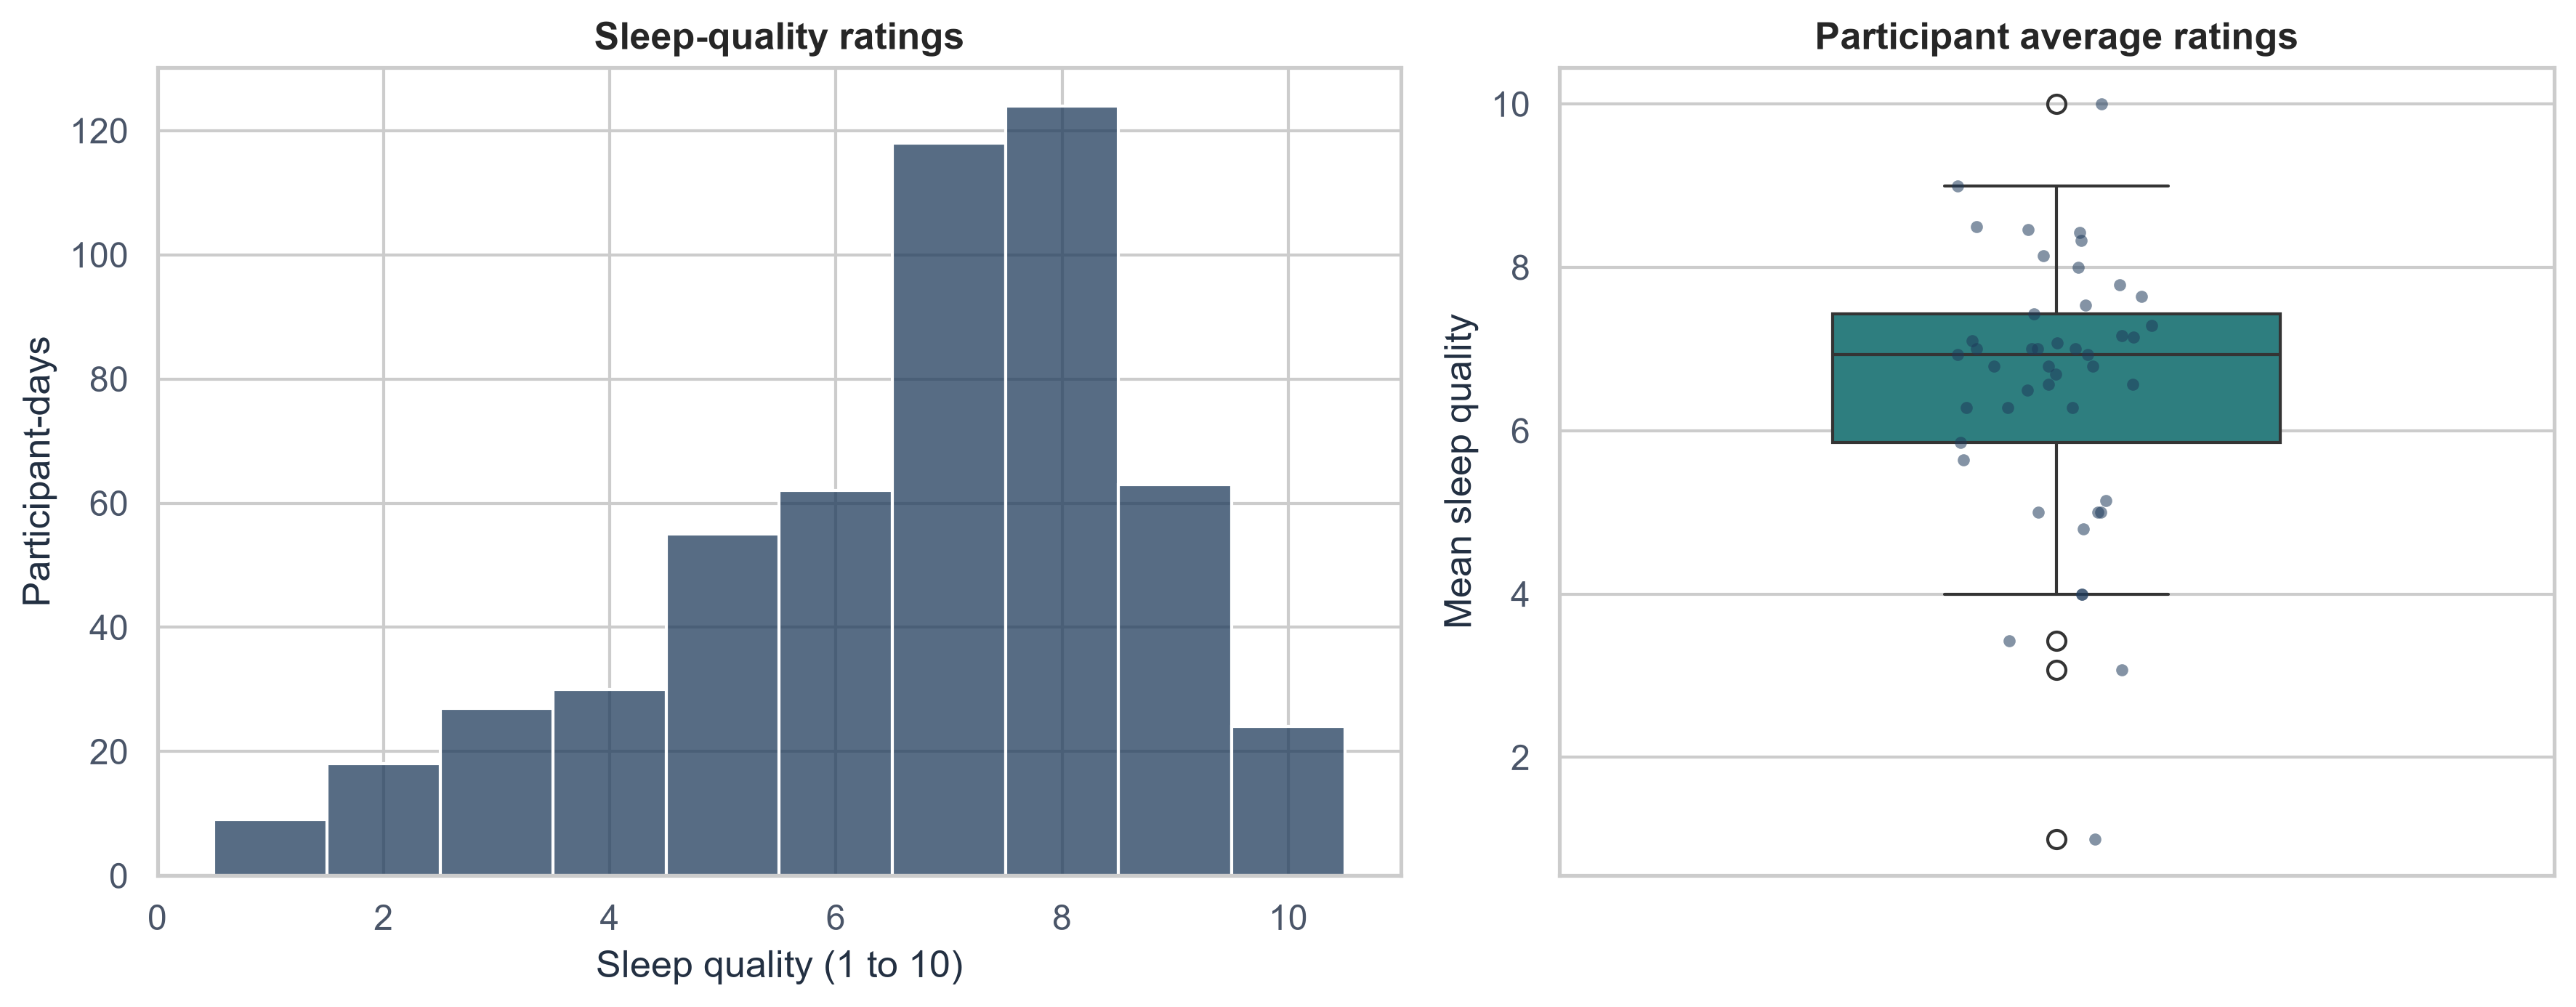

In [3]:
display(pd.read_csv(TABLES / "target_descriptives.csv").T.rename(columns={0: "value"}))
display(pd.read_csv(TABLES / "sleep_quality_distribution.csv"))
display(Image(filename=str(FIGURES / "02_sleep_quality_distribution.png")))

## Routine relationships and temporal patterns

Pooled relationships provide a starting point, but repeated measurements require caution. The association table includes sample sizes and Benjamini-Hochberg adjusted p-values for the defined family of correlations.

,predictor,column,n,spearman_rho,p_value,p_value_fdr_bh
0,Prior sleep quality,previous_sleep_quality,480,0.490,0.000,0.000
1,Prior sleep duration,previous_sleep_duration_hours,216,0.158,0.020,0.040
2,Screen time before bed,screen_time_before_bed_min,529,-0.157,0.000,0.001
3,Planned bedtime,planned_bedtime_hour,528,0.146,0.001,0.003
4,Stress level,stress_numeric,527,-0.108,0.013,0.034
5,Caffeine-to-bedtime hours,caffeine_to_planned_bedtime_hours,235,-0.075,0.251,0.418
6,Caffeine servings,caffeine_servings,530,-0.045,0.296,0.423
7,Total academic hours,total_academic_hours,529,-0.018,0.688,0.824
8,Exercise minutes,exercise_minutes,529,0.011,0.803,0.824
9,Nap minutes,nap_minutes,499,-0.010,0.824,0.824


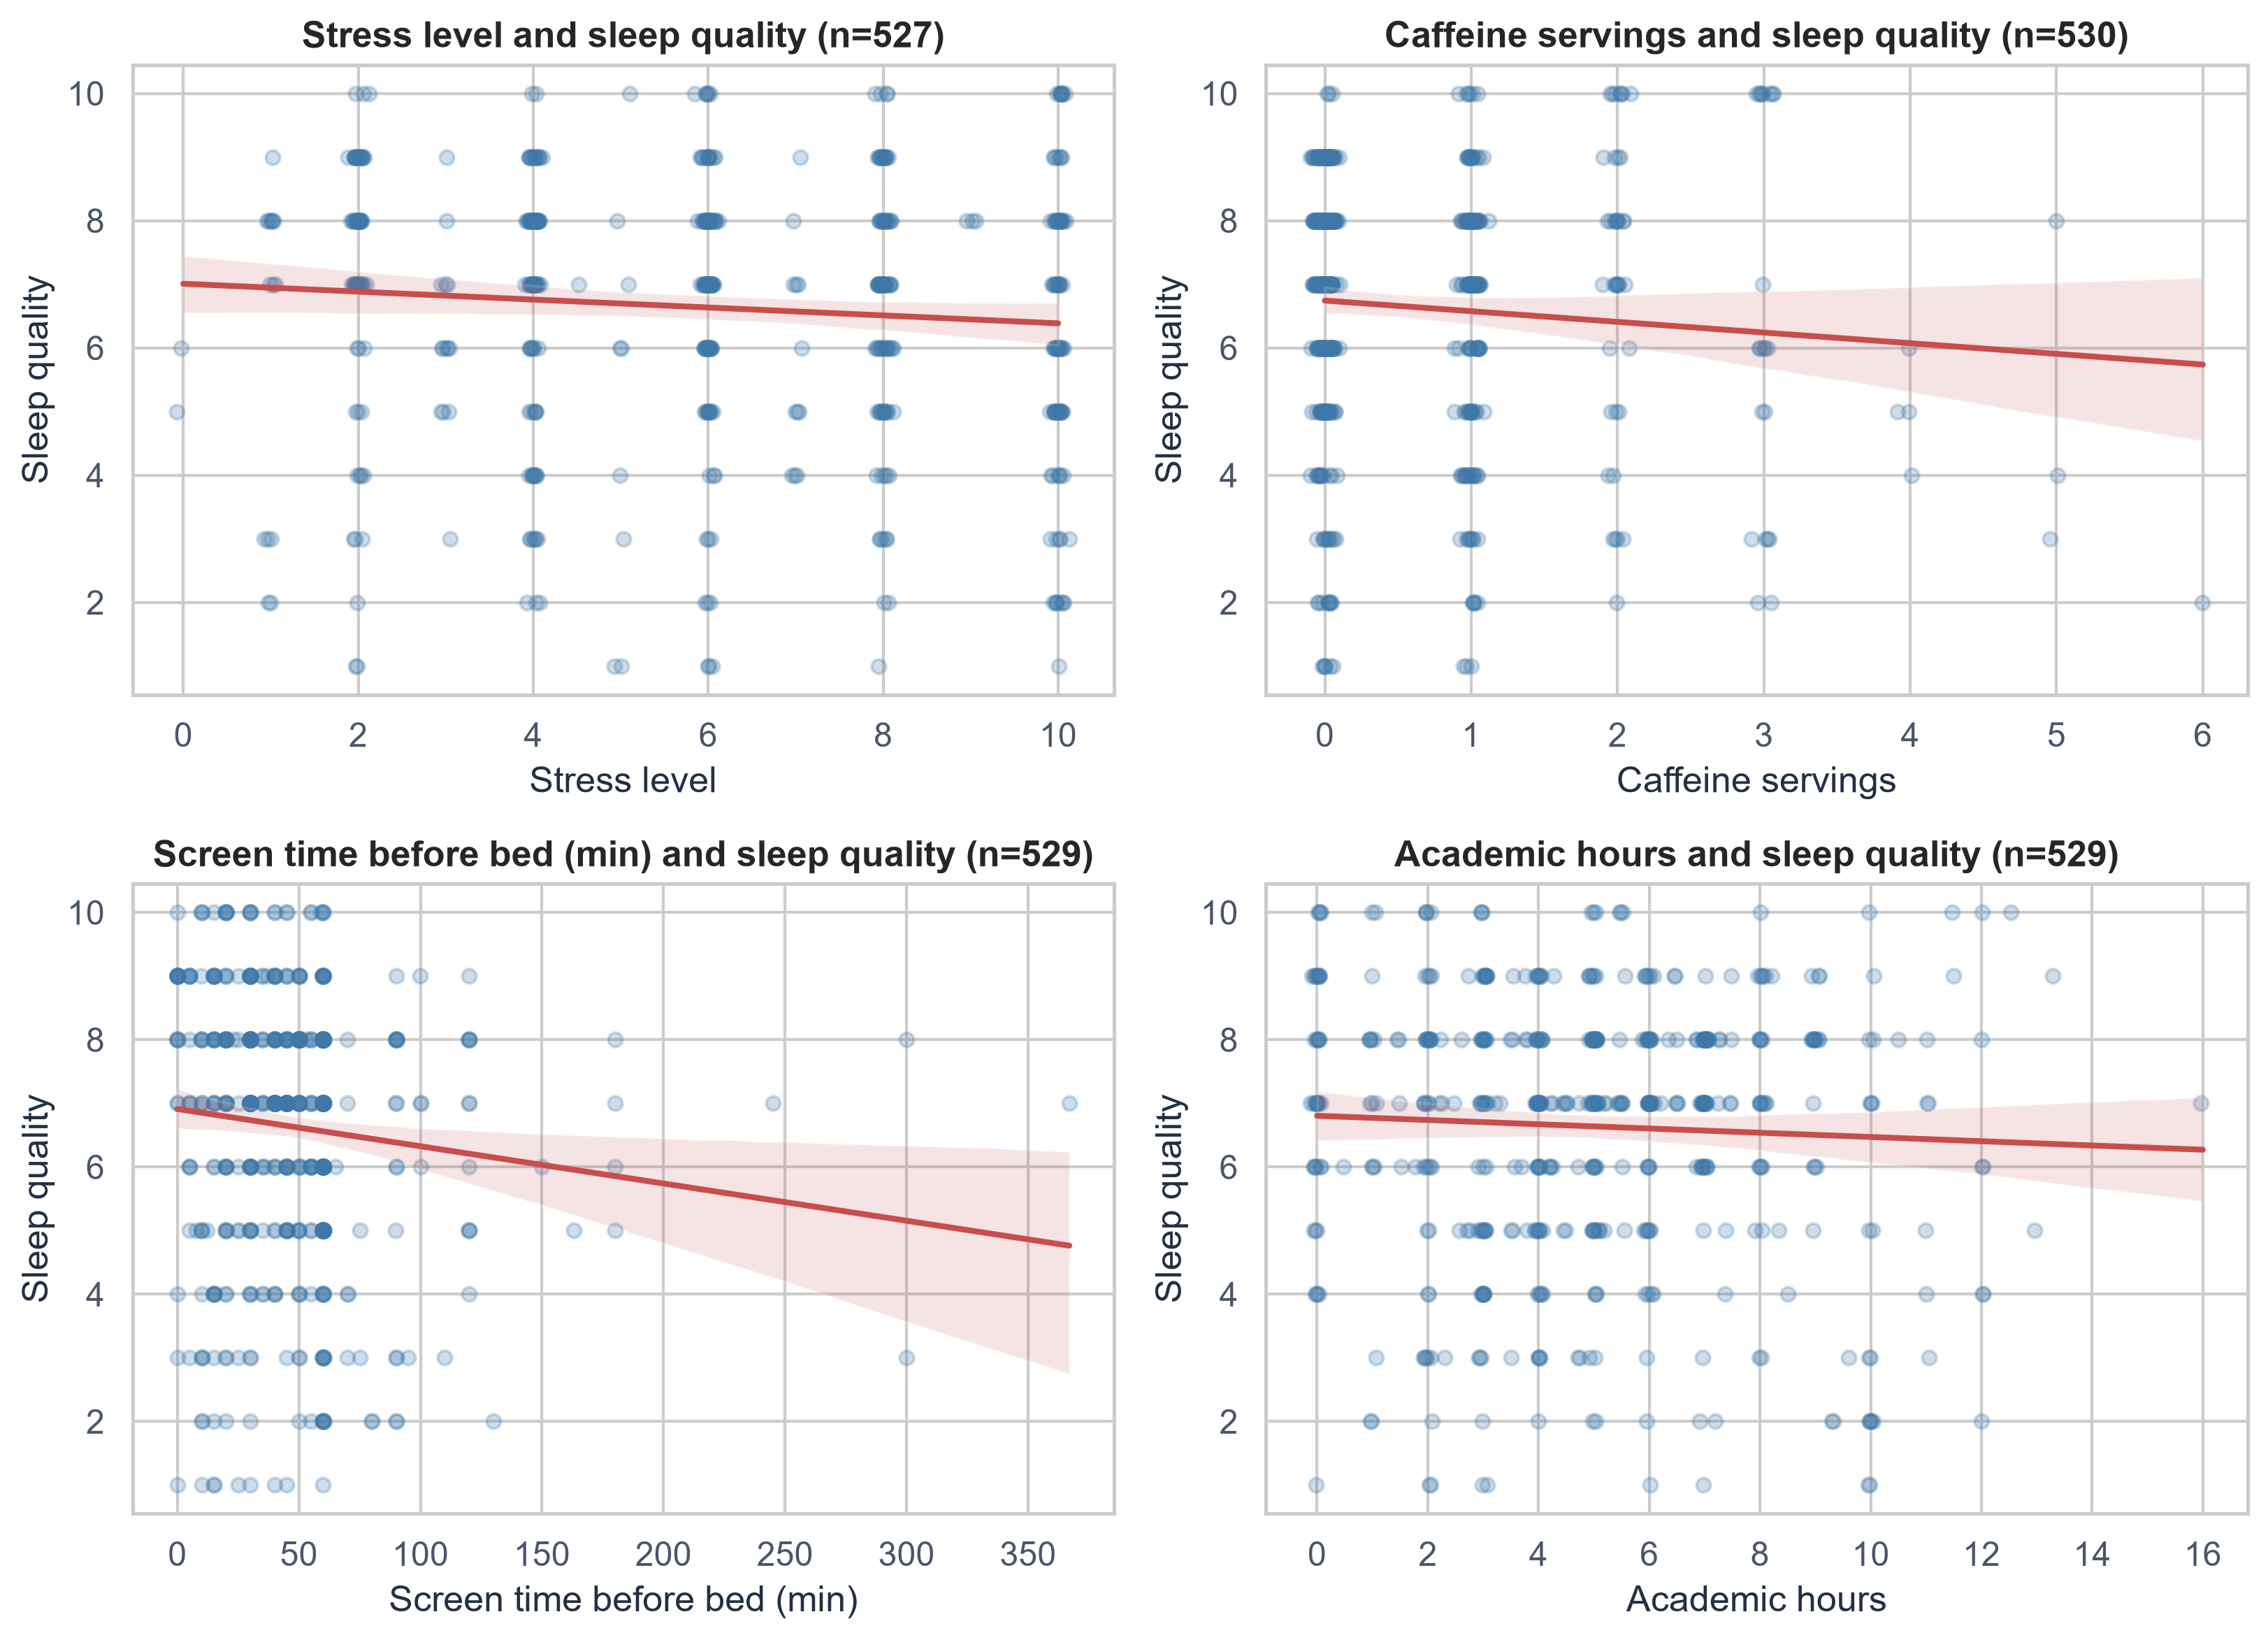

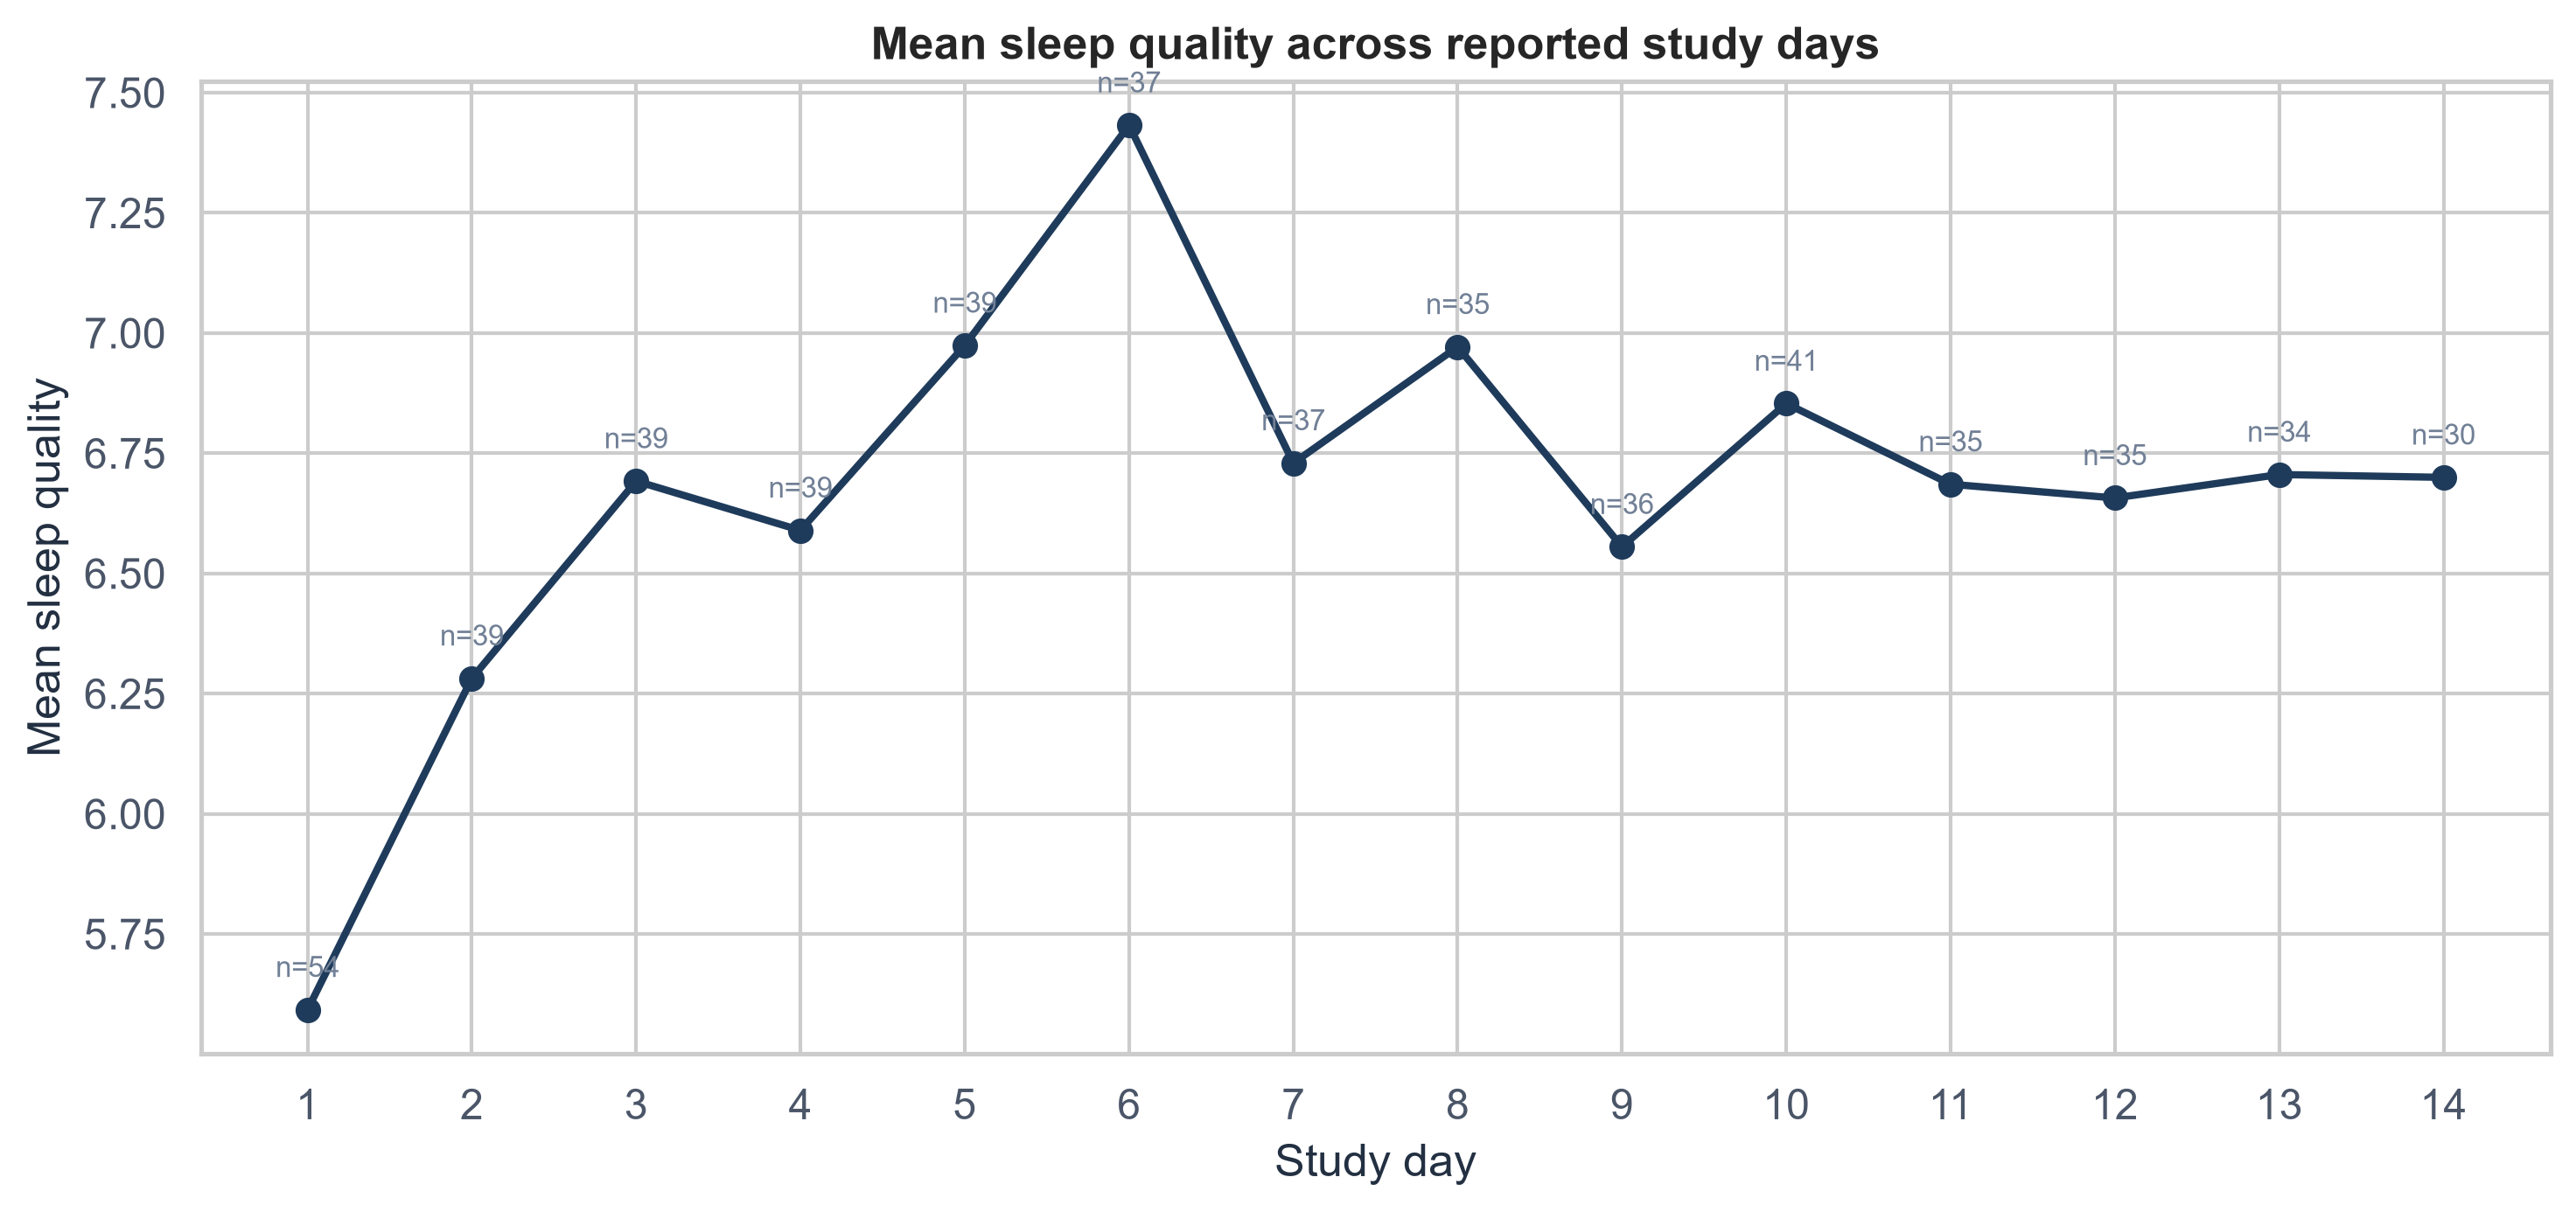

In [4]:
display(pd.read_csv(TABLES / "spearman_associations.csv").round(3))
display(Image(filename=str(FIGURES / "03_behavior_relationships.png")))
display(Image(filename=str(FIGURES / "05_temporal_pattern.png")))

## Within-person versus between-person stress

This retrospective model distinguishes a day's stress relative to the participant's own average from a student's typical stress relative to other participants. It uses participant-clustered standard errors. The result is inconclusive, so the notebook does not turn the weak pooled stress association into a behavioral claim.

,term,estimate,ci_low,ci_high,p_value,observations,participants,model
0,stress_numeric_within_person_z,-0.086,-0.259,0.086,0.326,525,43,OLS with participant-clustered standard errors
1,stress_between_person_z,-0.160,-0.607,0.288,0.484,525,43,OLS with participant-clustered standard errors


Sleep-quality ICC: {'icc': 0.43686917885200754, 'ci_low': 0.2683664197170559, 'ci_high': 0.5689786620050578, 'observations': 530, 'participants': 45, 'bootstrap_replicates': 500}


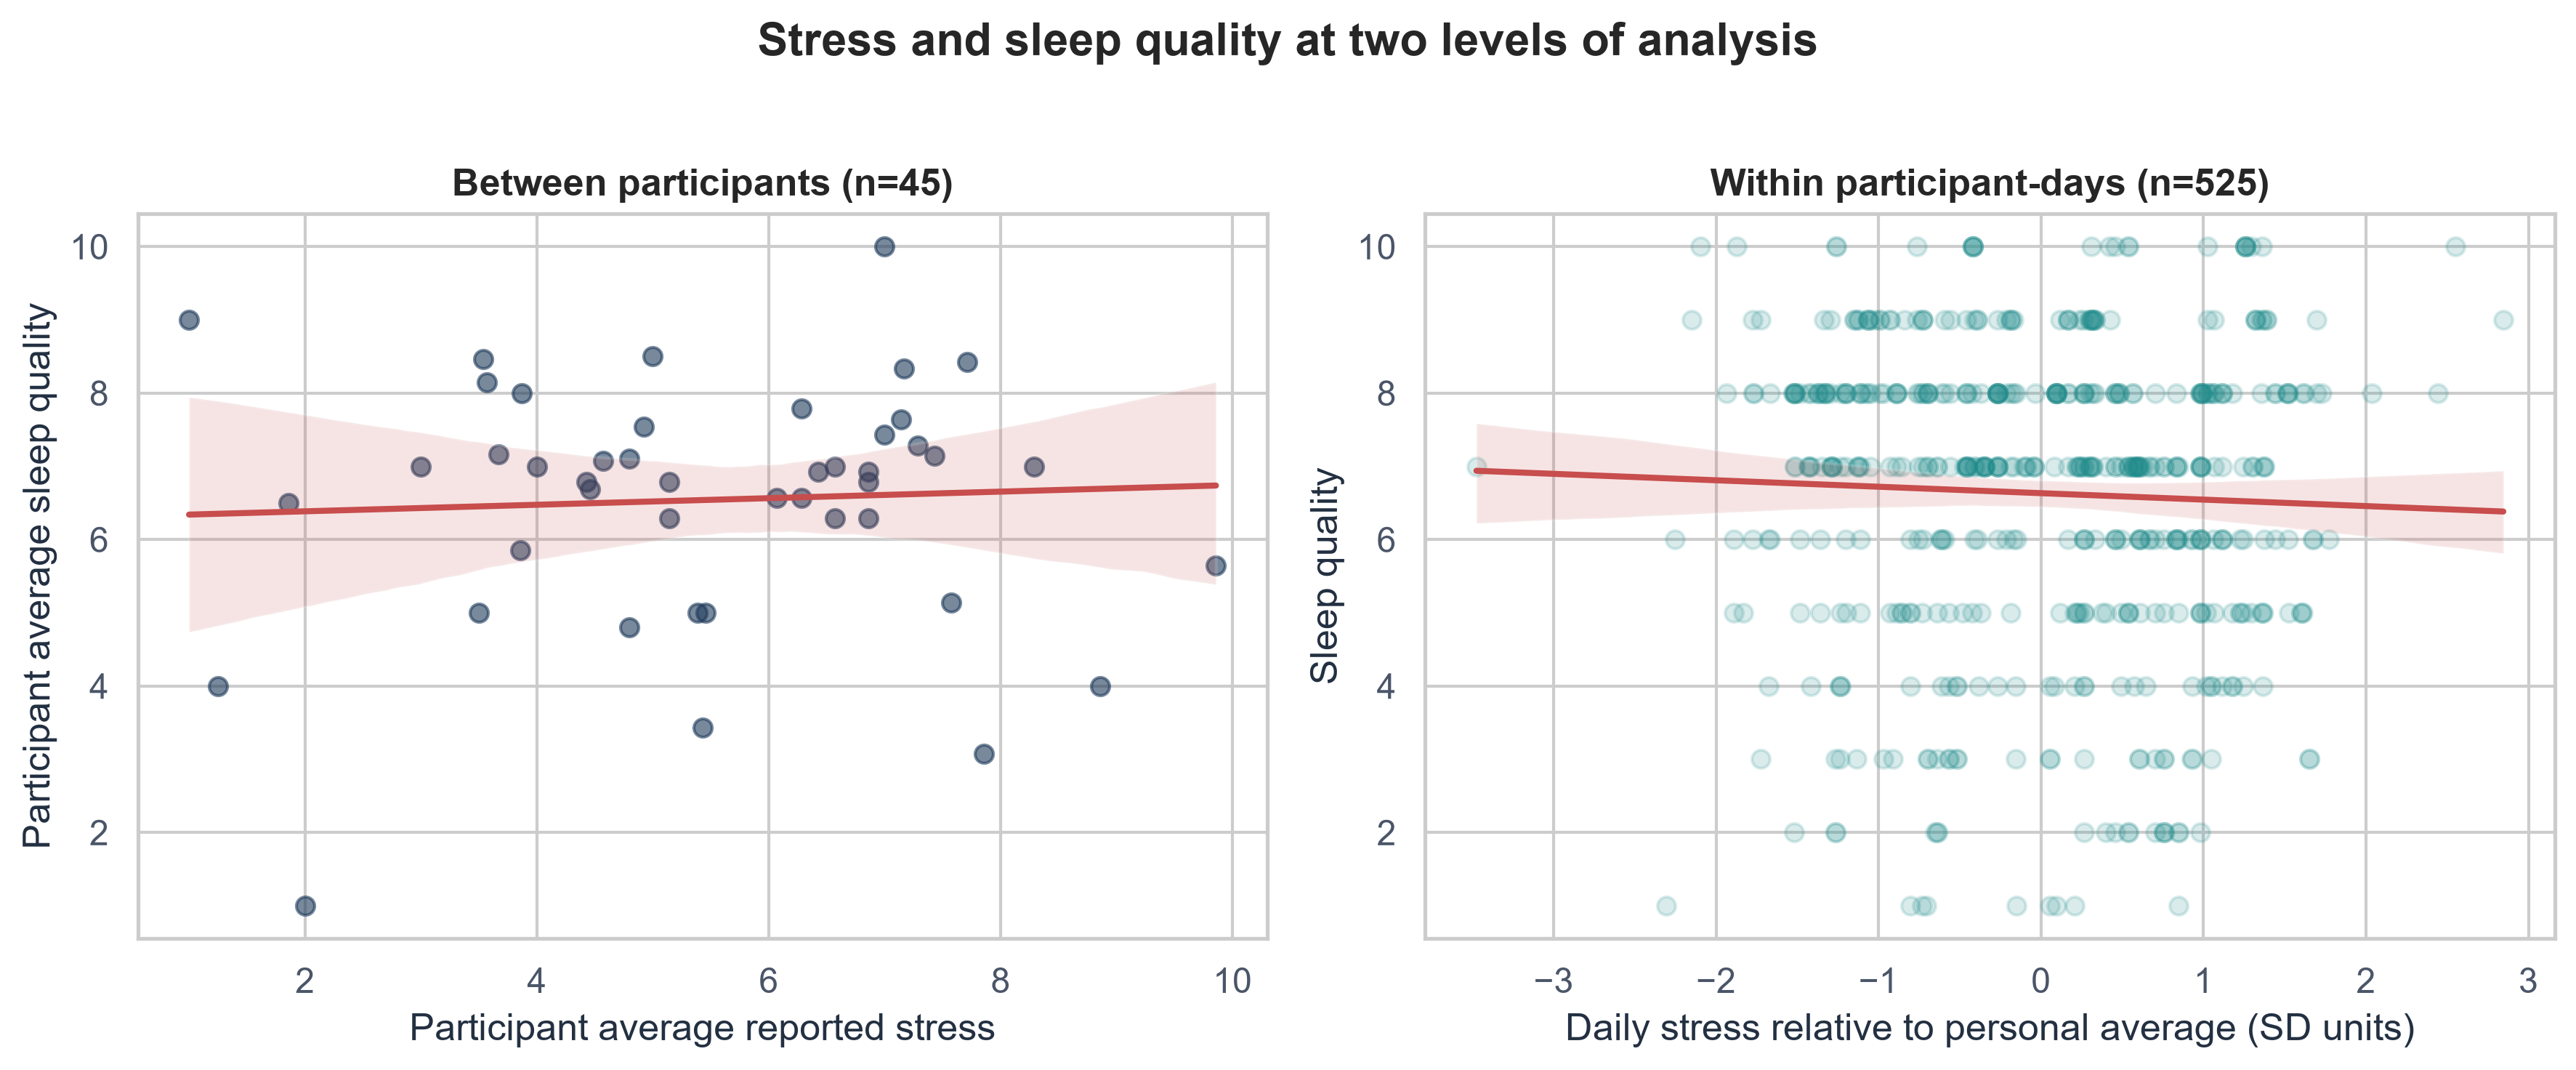

In [5]:
display(pd.read_csv(TABLES / "stress_mixed_model.csv").round(3))
print("Sleep-quality ICC:", results["icc"])
display(Image(filename=str(FIGURES / "04_within_between_stress.png")))

## Prediction design

The pipeline evaluates two different settings. GroupKFold holds out whole students and only uses target-night pre-sleep routines. Chronological forecasting holds out each known student's later records and permits only prior, shifted history. Current-night outcomes are prohibited by code-level leakage checks.

,model,scenario,n,mae,rmse,r2,median_ae,spearman_r,spearman_p,within_1
0,Global mean baseline,Unseen-participant group CV,530,1.687,2.112,-0.037,1.389,-0.228,0.000,0.340
1,Daytime Ridge,Unseen-participant group CV,530,1.820,2.323,-0.254,1.418,-0.105,0.016,0.353
2,Daytime Extra Trees,Unseen-participant group CV,530,1.753,2.247,-0.174,1.372,-0.118,0.006,0.358
3,Global mean baseline,Known-participant chronological forecast,183,1.714,2.123,-0.000,1.363,NaN,NaN,0.339
4,Previous-night sleep quality,Known-participant chronological forecast,180,1.311,1.865,0.236,1.000,0.527,0.000,0.650
5,Prior participant mean,Known-participant chronological forecast,183,1.341,1.766,0.308,1.000,0.508,0.000,0.508
6,Sleep-history Ridge,Known-participant chronological forecast,183,1.329,1.819,0.266,0.946,0.516,0.000,0.508
7,Behavioral Ridge,Known-participant chronological forecast,183,1.397,1.880,0.216,0.993,0.487,0.000,0.503
8,Personalized Ridge,Known-participant chronological forecast,183,1.561,2.141,-0.017,1.208,0.481,0.000,0.421
9,Personalized Extra Trees,Known-participant chronological forecast,183,1.302,1.689,0.367,1.086,0.559,0.000,0.443


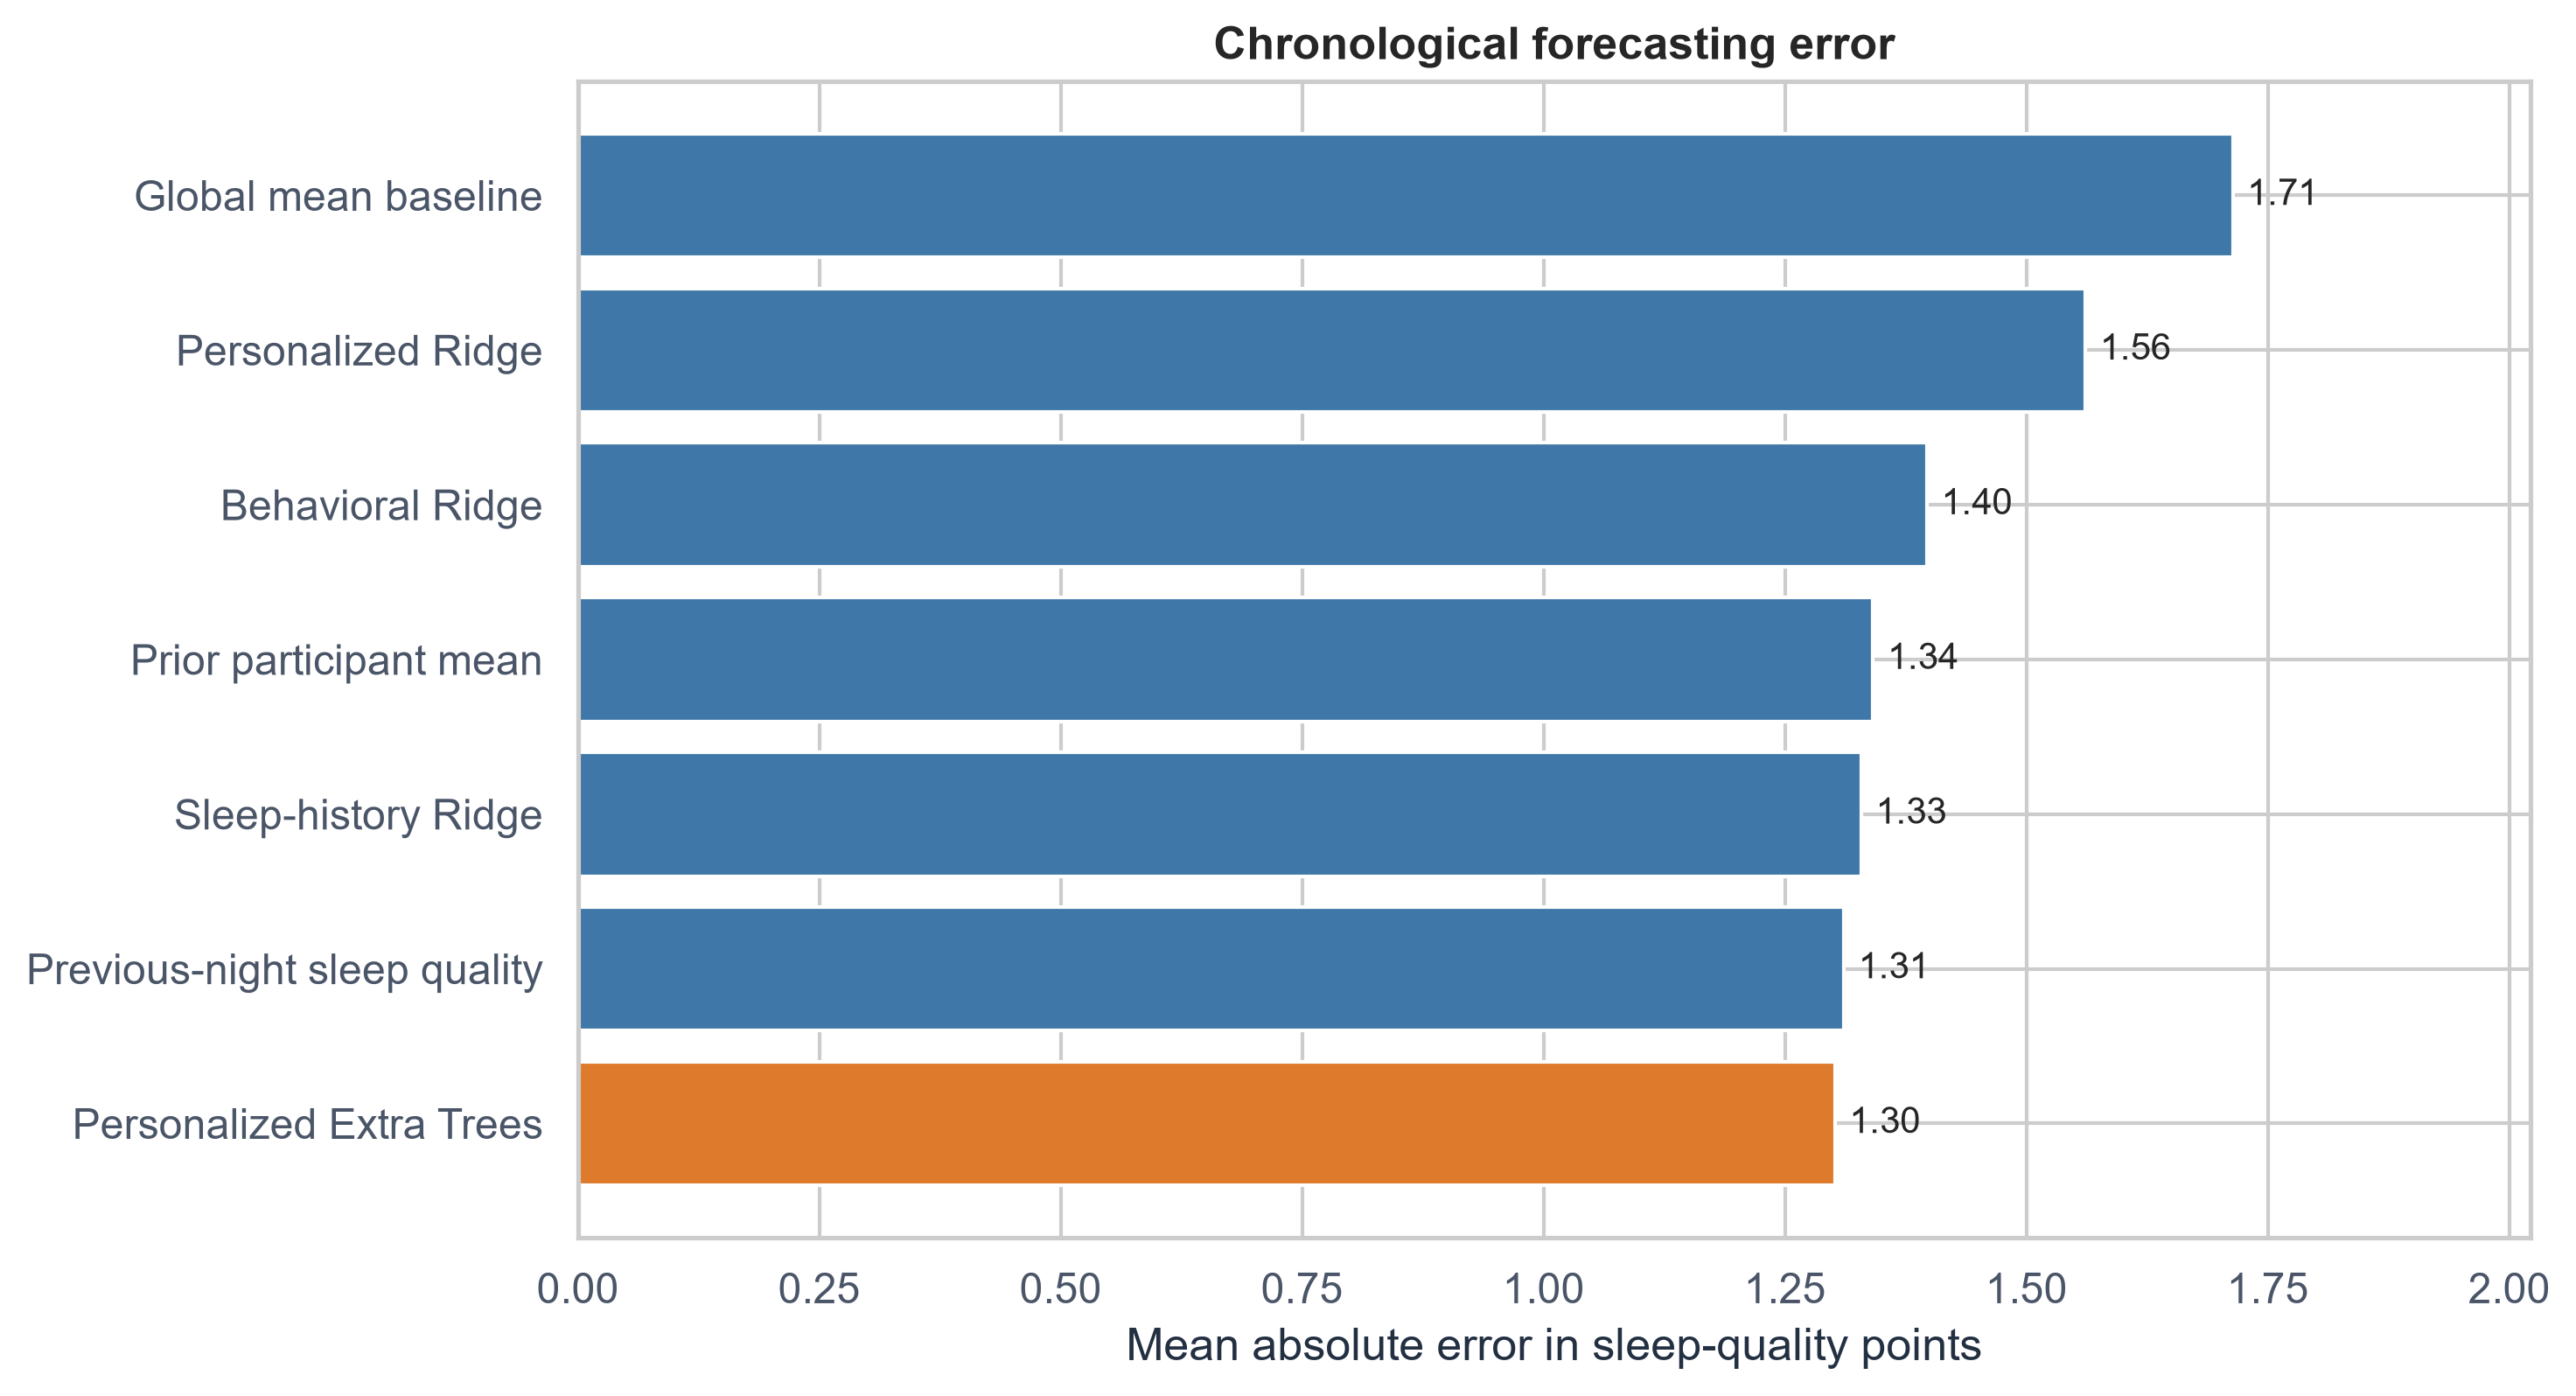

In [6]:
comparison = pd.read_csv(TABLES / "model_comparison.csv")
display(comparison.round(3))
display(Image(filename=str(FIGURES / "06_model_comparison.png")))

## Model interpretation and diagnostics

The best later-night forecast is only narrowly better than previous-night sleep quality. Feature importance is evaluated on held-out records. It identifies predictive contribution in this model, not a causal mechanism.

,feature,mae_increase_mean,mae_increase_sd
0,prior_3day_sleep_quality_mean,0.165,0.020
1,prior_sleep_quality_mean,0.136,0.013
2,previous_sleep_quality,0.057,0.015
3,late_caffeine_within_6h,0.019,0.004
4,previous_sleep_duration_hours,0.018,0.004
5,exercise_minutes_z_prior,0.015,0.007
6,stress_numeric,0.014,0.001
7,exercise_intensity,0.014,0.003
8,total_academic_hours,0.012,0.005
9,planned_bedtime_cos,0.009,0.003


Target-permutation check: {'permutations': 5, 'permuted_mae_mean': 1.7837425535605864, 'permuted_mae_sd': 0.05536923694913097}
Numeric-outcome sensitivity: {'n': 175, 'mae': 1.34468462585034, 'rmse': 1.7222576907515232, 'r2': 0.3680764951552795, 'median_ae': 1.1390793650793647, 'spearman_r': 0.5625628970757145, 'spearman_p': 5.408264005125786e-16, 'within_1': 0.4228571428571429}


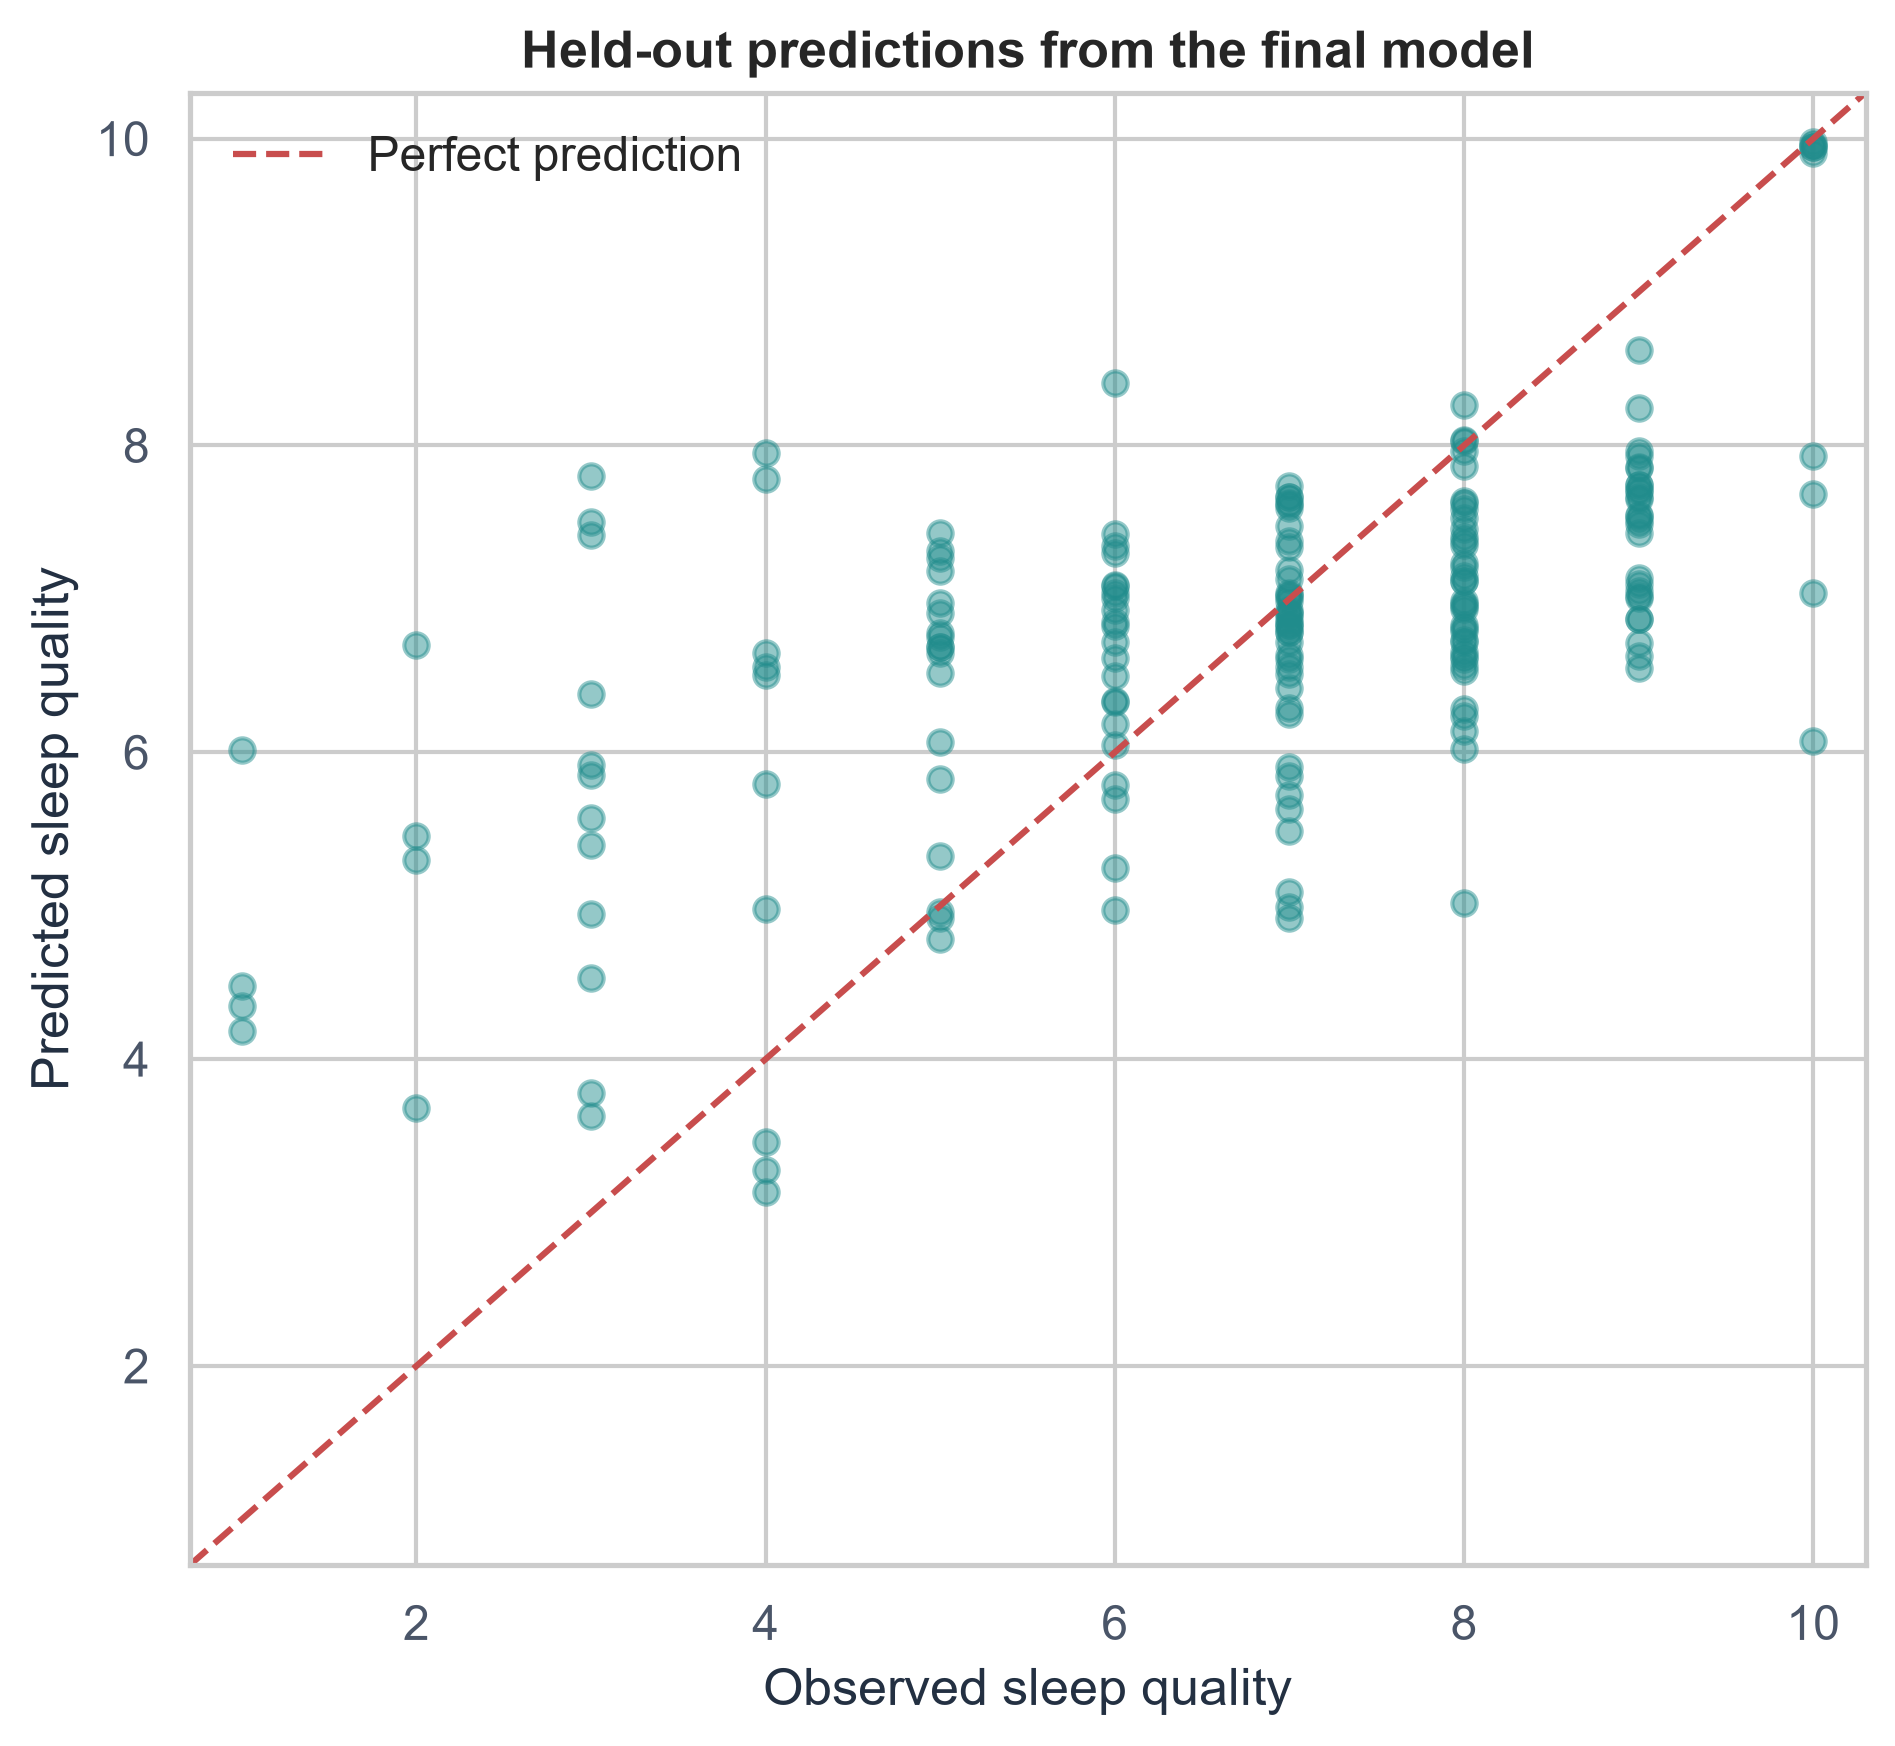

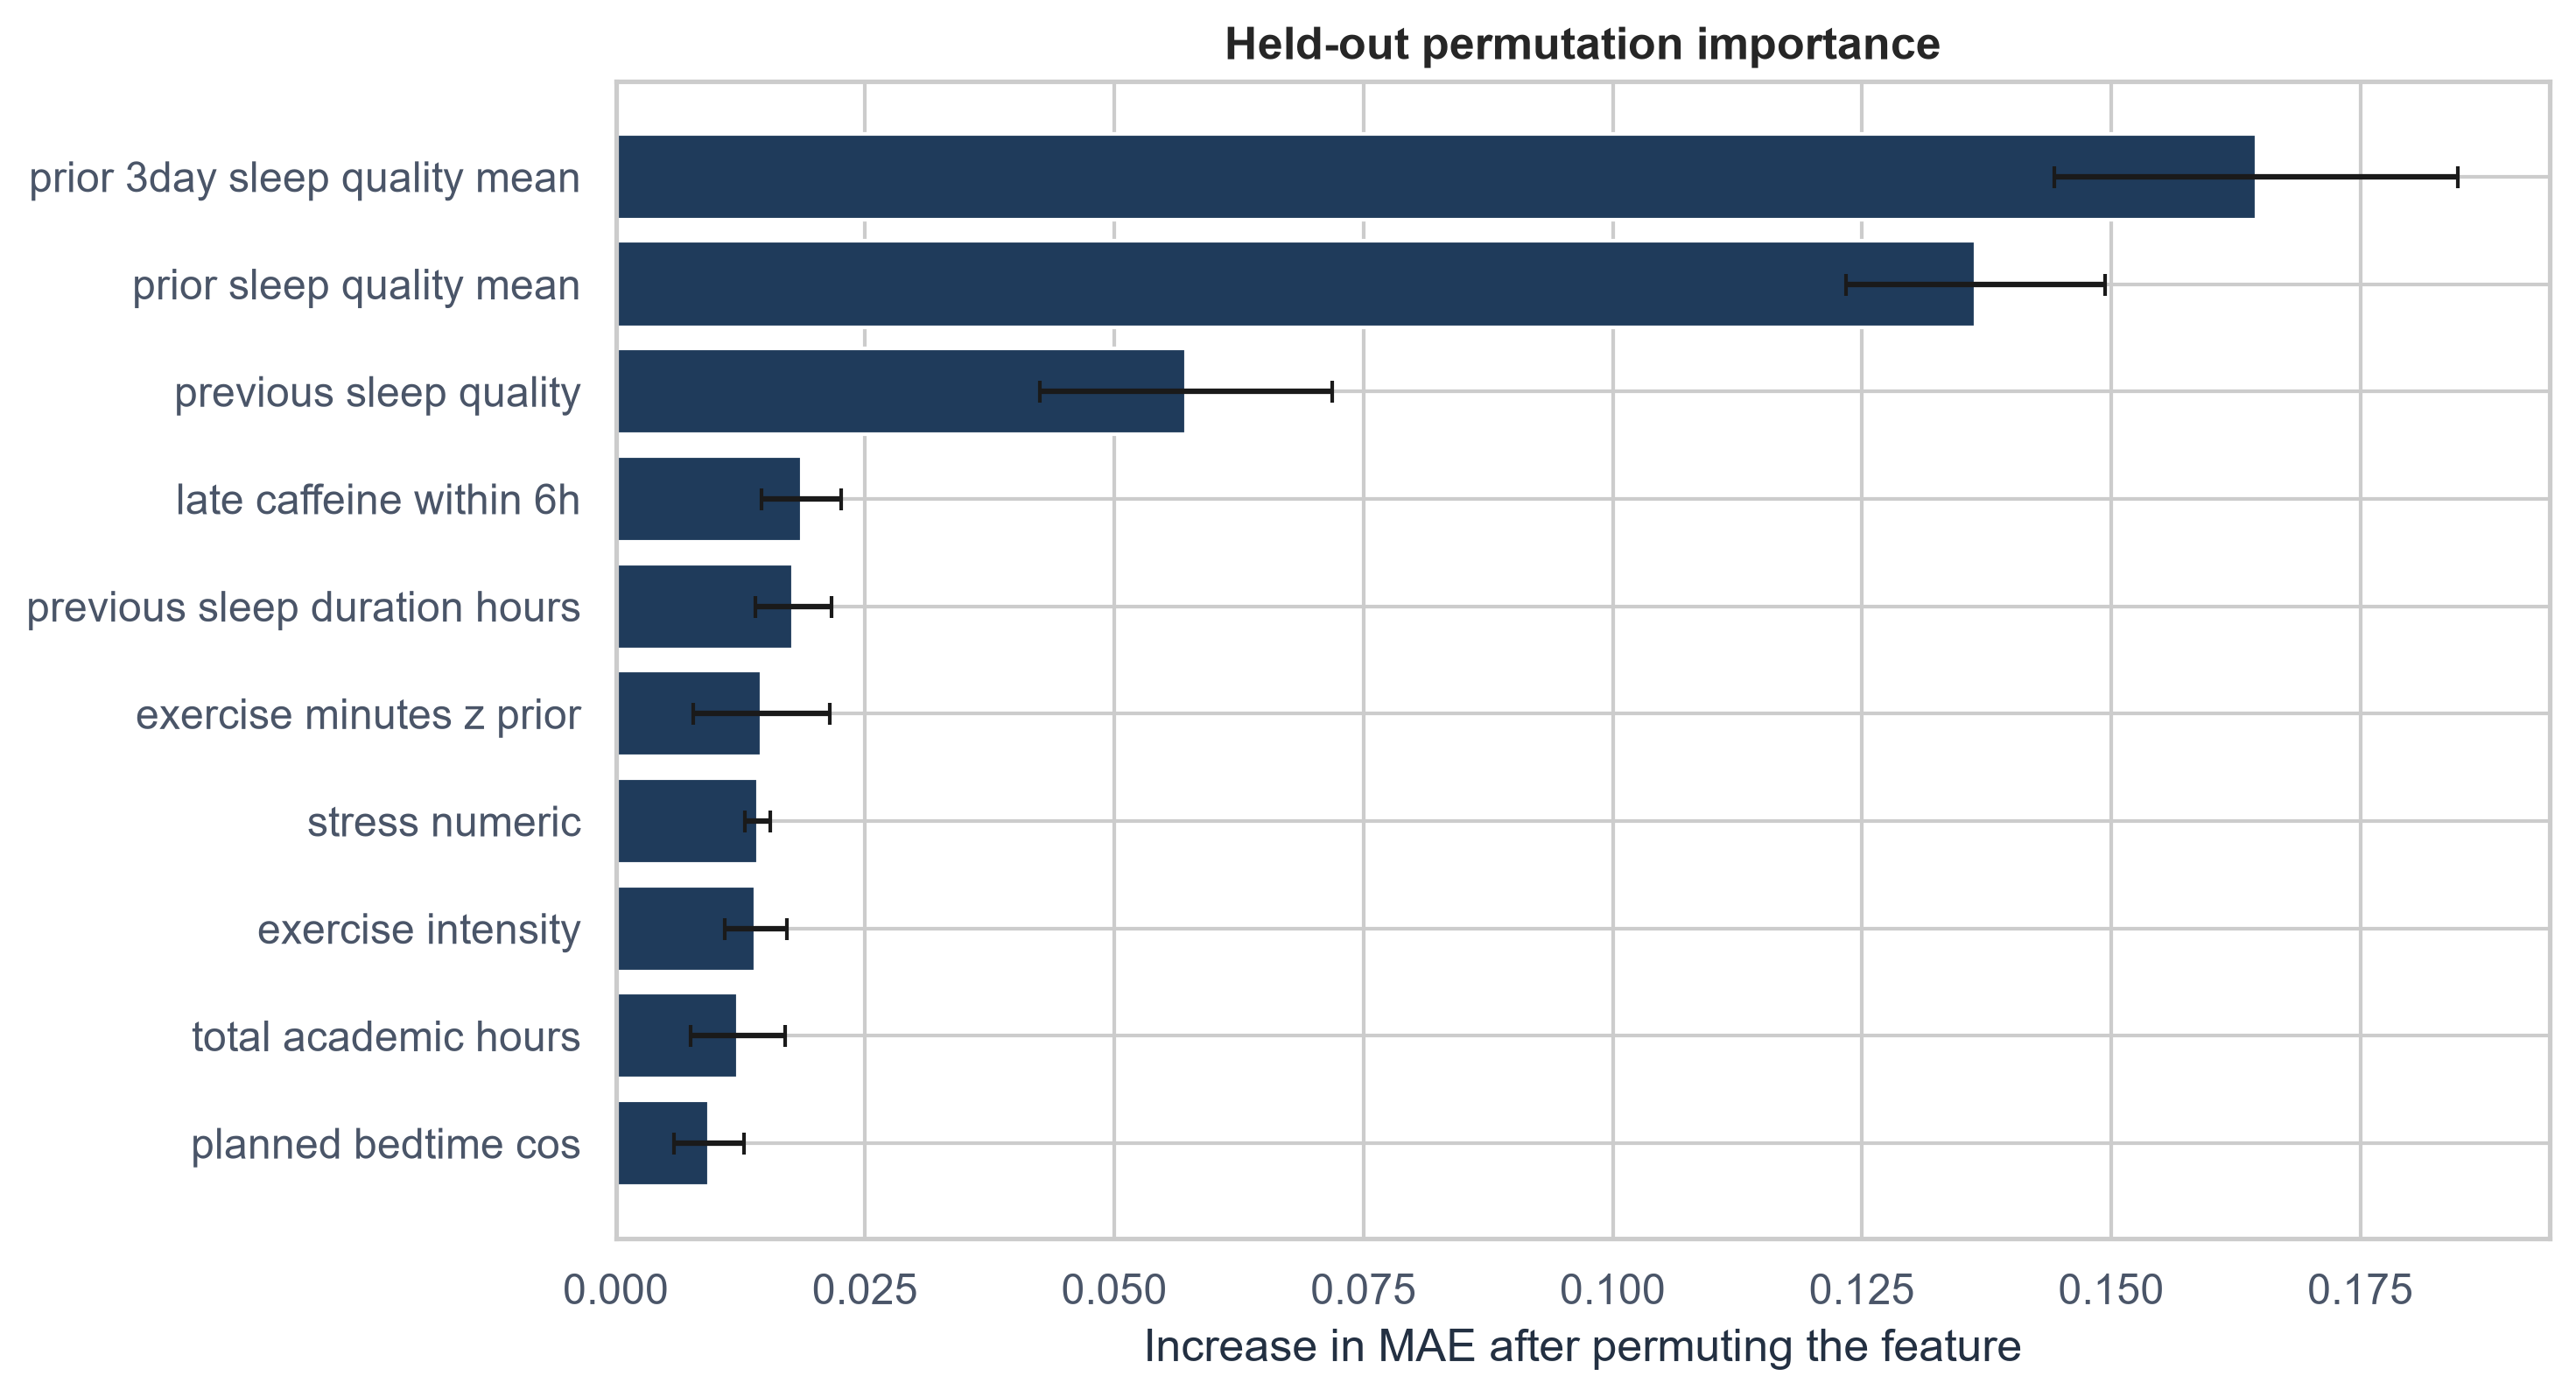

In [7]:
display(pd.read_csv(TABLES / "permutation_importance.csv").head(10).round(3))
print("Target-permutation check:", results["permutation_leakage_check"])
print("Numeric-outcome sensitivity:", results["numeric_target_sensitivity"])
display(Image(filename=str(FIGURES / "07_final_model_predictions.png")))
display(Image(filename=str(FIGURES / "08_feature_importance.png")))

## Wearable subset

Wearable values were optional. The table and figure describe only participants with observed wearable sleep duration, not the entire sample.

,measure,n,mean,sd,sleep_quality_spearman_rho,p_value
0,Wearable sleep duration (hours),239,7.484,1.362,0.322,0.000
1,Resting heart rate (bpm),116,62.216,5.423,-0.520,0.000
2,HRV (ms),56,61.750,8.697,0.789,0.000


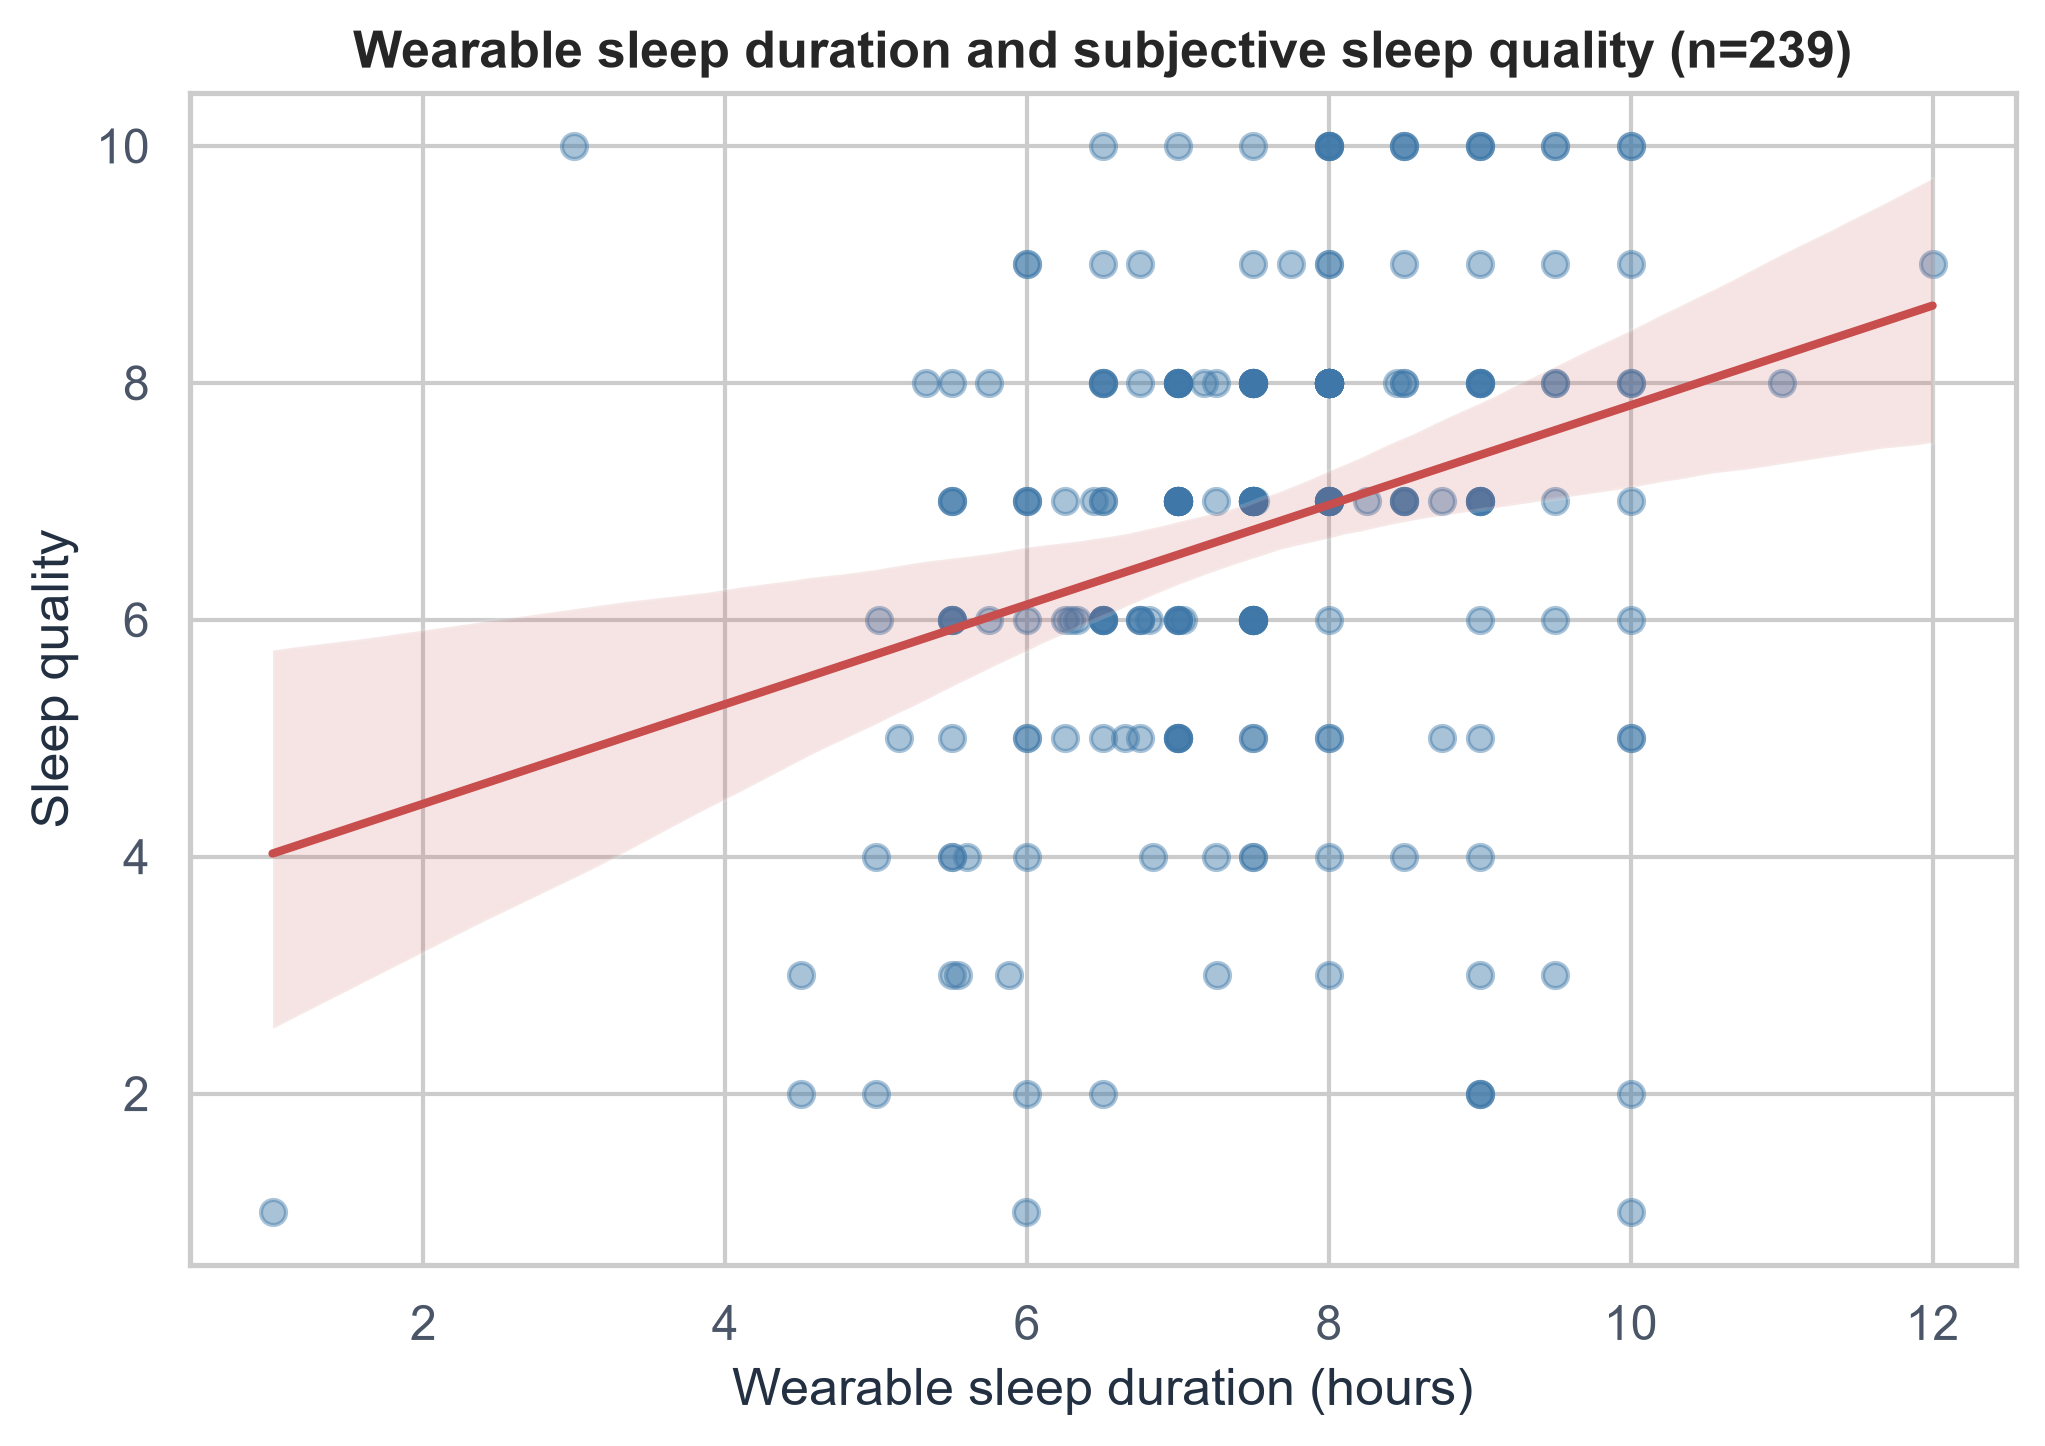

In [8]:
display(pd.read_csv(TABLES / "wearable_summary.csv").round(3))
display(Image(filename=str(FIGURES / "09_wearable_sleep_duration.png")))

## Conclusion

The strongest evidence supports individualized forecasting from earlier sleep history. Daytime routine models did not improve prediction for unseen students. The study does not show that changing any logged behavior will cause a change in sleep quality. See `reports/final_report.md` and `docs/LIMITATIONS.md` for the full interpretation.